In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import boto3
import requests
from io import BytesIO, StringIO
from sklearn.linear_model import LinearRegression
import os

In [26]:
os.environ["AWS_ACCESS_KEY_ID"] = "------"
os.environ["AWS_SECRET_ACCESS_KEY"] = "------"
os.environ["AWS_SESSION_TOKEN"] = "------"
os.environ["AWS_DEFAULT_REGION"] = "us-east-1"

In [27]:
# --------------------------------------------------
# CONNECT TO AMAZON S3
# --------------------------------------------------

s3 = boto3.client("s3")

bucket_name = "charlotte-gas-price-project-dtsc3601"

print("Connected to Amazon S3!")

Connected to Amazon S3!


In [28]:
# --------------------------------------------------
# INGEST CURRENT GAS PRICE DATA FROM GITHUB API
# --------------------------------------------------

# GitHub API endpoint for the metro gas price folder
api_url = (
    "https://api.github.com/repos/lykmapipo/"
    "US-Gas-Prices/contents/data/metro-daily-averages"
)

# Request the list of files from GitHub
response = requests.get(api_url, timeout=30)
response.raise_for_status()

files = response.json()

# Keep only CSV files
csv_files = [
    file for file in files
    if file["name"].endswith(".csv")
]

# Sort by filename because filenames contain dates
csv_files = sorted(
    csv_files,
    key=lambda x: x["name"]
)

# Select newest CSV
latest_file = csv_files[-1]

print("Latest file found through API:")
print(latest_file["name"])

Latest file found through API:
2026-09-26.csv


In [29]:
# Download the newest CSV
download_url = latest_file["download_url"]

csv_response = requests.get(
    download_url,
    timeout=30
)

csv_response.raise_for_status()

# Convert downloaded CSV into a DataFrame
api_data = pd.read_csv(
    StringIO(csv_response.text)
)

print("\nData retrieved through API:")
display(api_data.head())


Data retrieved through API:


,State-Name,State-Abbreviation,Metro-Name,Regular,Mid-Grade,Premium,Diesel,Currency,Unit,Date
0,Alaska,AK,Anchorage,5.0011,5.2777,5.5194,6.6344,U.S Dollar,US Gallon,2026-09-26
1,Alaska,AK,Fairbanks,5.0376,5.3009,5.5355,6.7790,U.S Dollar,US Gallon,2026-09-26
2,Alaska,AK,Juneau,4.7508,4.8876,4.9890,6.4340,U.S Dollar,US Gallon,2026-09-26
3,Alabama,AL,Anniston-Oxford,4.0564,4.5203,4.9183,6.0845,U.S Dollar,US Gallon,2026-09-26
4,Alabama,AL,Auburn,4.0602,4.5285,4.9330,6.0432,U.S Dollar,US Gallon,2026-09-26


In [30]:
# --------------------------------------------------
# FILTER API DATA TO CHARLOTTE
# --------------------------------------------------

charlotte_api_data = api_data[
    (api_data["State-Abbreviation"] == "NC") &
    (api_data["Metro-Name"].str.contains("Charlotte", case=False, na=False))
].copy()

print("Current Charlotte gas price data retrieved from API:")
display(charlotte_api_data)

Current Charlotte gas price data retrieved from API:


,State-Name,State-Abbreviation,Metro-Name,Regular,Mid-Grade,Premium,Diesel,Currency,Unit,Date
258,North Carolina,NC,Charlotte-Gastonia-Rock Hill (NC only),4.1932,4.6764,5.0645,6.1508,U.S Dollar,US Gallon,2026-09-26


In [31]:
# --------------------------------------------------
# UPLOAD API DATA TO AMAZON S3
# --------------------------------------------------

csv_buffer = StringIO()

charlotte_api_data.to_csv(
    csv_buffer,
    index=False
)

s3.put_object(
    Bucket=bucket_name,
    Key="raw-data/current_charlotte_gas_prices.csv",
    Body=csv_buffer.getvalue()
)

print("Current Charlotte API data successfully uploaded to S3!")

Current Charlotte API data successfully uploaded to S3!


In [32]:
# --------------------------------------------------
# LOAD TRAINING DATA FROM AMAZON S3
# --------------------------------------------------

bucket_name = "charlotte-gas-price-project-dtsc3601"
file_key = "processed-data/charlotte_nc_gas_prices_weekly.csv"

response = s3.get_object(
    Bucket=bucket_name,
    Key=file_key
)

data = pd.read_csv(
    BytesIO(response["Body"].read())
)

print("Training data successfully loaded from S3!")
display(data.head())

Training data successfully loaded from S3!


,Week_Ending,Regular,MidGrade,Premium,Diesel
0,2023-12-31,3.019,3.452,3.818,3.958
1,2024-02-04,3.024,3.455,3.816,3.847
2,2024-09-15,2.939,3.379,3.745,3.476
3,2024-09-22,2.913,3.362,3.726,3.452
4,2024-09-29,2.968,3.408,3.770,3.446


In [33]:
# Make sure dates are dates
data["Week_Ending"] = pd.to_datetime(data["Week_Ending"])

In [34]:
# Sort by date
data = data.sort_values("Week_Ending")

In [35]:
# Turn dates into numbers
data["day_number"] = (
    data["Week_Ending"] - data["Week_Ending"].min()
).dt.days

In [36]:
# X = what we use to make the prediction
# y = what we are predicting
X = data[["day_number"]]
y = data["Regular"]

In [37]:
# Create and train the model
model = LinearRegression()
model.fit(X, y)

LinearRegression()

In [38]:
# Print the equation
print("Linear Regression Equation:")
print(f"Gas Price = {model.intercept_:.2f} + "
      f"({model.coef_[0]:.4f} × Day Number)")

Linear Regression Equation:
Gas Price = 2.38 + (0.0012 × Day Number)


In [39]:
# Print R-squared
print(f"\nR-squared: {model.score(X, y):.2f}")


R-squared: 0.37


In [40]:
# Predictions for historical data
predicted = model.predict(X)

In [41]:
# Create future dates
future_dates = pd.date_range(
    start="2026-10-04",
    periods=52,
    freq="W-SUN"
)

In [42]:
# Turn future dates into numbers
future_days = (
    future_dates - data["Week_Ending"].min()
).days

In [43]:
# Predict future gas prices
future_predictions = model.predict(
    pd.DataFrame({"day_number": future_days})
)

In [44]:
# Print future predictions
print("\nFuture Gas Price Predictions:")

for date, price in zip(future_dates, future_predictions):
    print(date.date(), f"${price:.2f}")


Future Gas Price Predictions:
2026-10-04 $3.57
2026-10-11 $3.58
2026-10-18 $3.59
2026-10-25 $3.60
2026-11-01 $3.61
2026-11-08 $3.62
2026-11-15 $3.62
2026-11-22 $3.63
2026-11-29 $3.64
2026-12-06 $3.65
2026-12-13 $3.66
2026-12-20 $3.67
2026-12-27 $3.67
2027-01-03 $3.68
2027-01-10 $3.69
2027-01-17 $3.70
2027-01-24 $3.71
2027-01-31 $3.72
2027-02-07 $3.72
2027-02-14 $3.73
2027-02-21 $3.74
2027-02-28 $3.75
2027-03-07 $3.76
2027-03-14 $3.77
2027-03-21 $3.77
2027-03-28 $3.78
2027-04-04 $3.79
2027-04-11 $3.80
2027-04-18 $3.81
2027-04-25 $3.81
2027-05-02 $3.82
2027-05-09 $3.83
2027-05-16 $3.84
2027-05-23 $3.85
2027-05-30 $3.86
2027-06-06 $3.86
2027-06-13 $3.87
2027-06-20 $3.88
2027-06-27 $3.89
2027-07-04 $3.90
2027-07-11 $3.91
2027-07-18 $3.91
2027-07-25 $3.92
2027-08-01 $3.93
2027-08-08 $3.94
2027-08-15 $3.95
2027-08-22 $3.96
2027-08-29 $3.96
2027-09-05 $3.97
2027-09-12 $3.98
2027-09-19 $3.99
2027-09-26 $4.00


In [71]:
# --------------------------------------------------
# LIVE GAS PRICE PREDICTION
# --------------------------------------------------

print("--- Live Gas Price Prediction ---")

user_date = input("Enter a future date (YYYY-MM-DD): ")

forecast_date = pd.to_datetime(user_date)

day_number = (
    forecast_date - data["Week_Ending"].min()
).days

live_input = pd.DataFrame({
    "day_number": [day_number]
})

live_prediction = model.predict(live_input)[0]

print(
    f"\nPredicted average Regular gas price "
    f"for {forecast_date.date()}: "
    f"${live_prediction:.2f} per gallon"
)

--- Live Gas Price Prediction ---


Enter a future date (YYYY-MM-DD):  2027-12-03



Predicted average Regular gas price for 2027-12-03: $4.08 per gallon


In [73]:
# --------------------------------------------------
# CREATE CSV FOR ARCGIS
# --------------------------------------------------

results = pd.DataFrame({
    "Week_Ending": future_dates.date,
    "Predicted_Regular_Price": future_predictions.round(2),

    # Charlotte coordinates
    "Latitude": 35.2271,
    "Longitude": -80.8431
})

# Save the CSV
results.to_csv(
    r"C:\Users\Rachel\Downloads\gas_price_predictions_next_year.csv",
    index=False
)

print("\nCSV saved as:")
print(r"C:\Users\Rachel\Downloads\gas_price_predictions_next_year.csv")


CSV saved as:
C:\Users\Rachel\Downloads\gas_price_predictions_next_year.csv


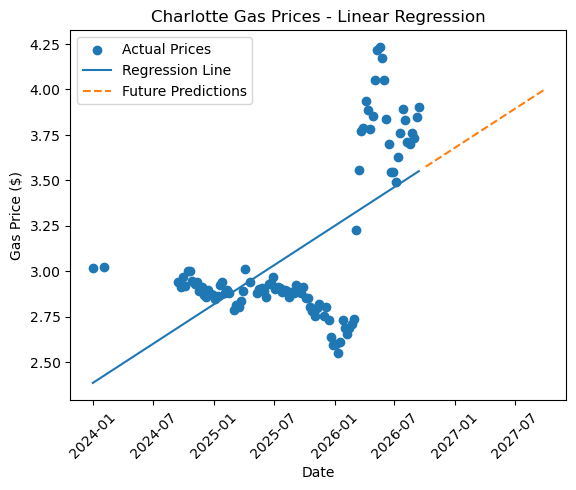

In [46]:
# --------------------------------------------------
# GRAPH
# --------------------------------------------------

plt.scatter(
    data["Week_Ending"],
    y,
    label="Actual Prices"
)

plt.plot(
    data["Week_Ending"],
    predicted,
    label="Regression Line"
)

plt.plot(
    future_dates,
    future_predictions,
    "--",
    label="Future Predictions"
)

plt.xlabel("Date")
plt.ylabel("Gas Price ($)")
plt.title("Charlotte Gas Prices - Linear Regression")
plt.legend()
plt.xticks(rotation=45)
plt.show()